# Gaussian-1000D WFR

Train the WFR model and reproduce its trajectory and growth panels.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import compute_uot_plans
import math


# Compute WFR semi-couplings between two snapshots.
def compute_exact_wfr_semi_coupling(X0, X1, delta):


    _, gamma0s, gamma1s, _ = compute_uot_plans([X0, X1], [0, 1], delta, False, cuda=torch.cuda.is_available())

    Gamma1_exact = gamma0s[0]
    Gamma2_exact = gamma1s[0]
    return torch.from_numpy(Gamma1_exact), torch.from_numpy(Gamma2_exact)

# Parameterize the single-particle position and mass path.
class RUOT_TrajectoryNet(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()


        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, d, m, t):


        log_m = torch.log(m + 1e-12)


        features = torch.stack([d, log_m, t], dim=-1)
        out = self.net(features)

        net_m = out[..., 0]
        net_x = out[..., 1]


        m_t = (m ** t) * torch.exp(t * (1 - t) * net_m)


        x_t = d * (t + t * (1 - t) * net_x)

        return m_t, x_t


import math

def compute_action_loss(model, Psi_func, batch_size, device):


    steps = int(math.sqrt(batch_size))


    d_axis = torch.linspace(0.1, 12.1, steps, device=device)
    m_axis = torch.linspace(0.01, 10.1, steps, device=device)


    D_grid, M_grid = torch.meshgrid(d_axis, m_axis, indexing='ij')


    d = D_grid.reshape(-1)
    m = M_grid.reshape(-1)


    actual_batch = d.shape[0]


    t = torch.rand(actual_batch, device=device).requires_grad_(True)


    m_t, x_t = model(d, m, t)


    m_dot = torch.autograd.grad(
        outputs=m_t,
        inputs=t,
        grad_outputs=torch.ones_like(m_t),
        create_graph=True,
        retain_graph=True
    )[0]

    x_dot = torch.autograd.grad(
        outputs=x_t,
        inputs=t,
        grad_outputs=torch.ones_like(x_t),
        create_graph=True,
        retain_graph=True
    )[0]


    m_t_safe = torch.clamp(m_t, min=1e-6)

    kinetic_term = x_dot ** 2
    mass_penalty_term = Psi_func(m_dot / m_t_safe)

    action_density = 0.5 * (kinetic_term + mass_penalty_term) * m_t


    return action_density.mean()


def train_ruot_pinn(model_class, Psi_func, epochs=5000, batch_size=1024, lr=2e-3, device='cuda'):

    model = model_class().to(device)


    optimizer = optim.Adam(model.parameters(), lr=lr)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    model.train()
    print(f"🚀 Starting PINN Training on {device} (Batch={batch_size})")

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()


        loss = compute_action_loss(model, Psi_func, batch_size, device)


        loss.backward()


        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()


        if epoch % 500 == 0 or epoch == 1:
            current_lr = scheduler.get_last_lr()[0]
            print(f"Epoch [{epoch:4d}/{epochs}] | Action Loss: {loss.item():.6e} | LR: {current_lr:.2e}")

    print("✅ Training Complete! The neural surrogate now approximates the optimal trajectory.")
    model.eval()
    return model


# Approximate the symmetric dynamic transport cost.
class RUOT_SymmetricModel(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward_old(self, d, ratio):


        u = torch.abs(torch.log(ratio + 1e-12))


        u = torch.clamp(u, max=4.6)


        features = torch.stack([d, u], dim=-1)


        out = self.net(features).squeeze(-1)


        S = F.softplus(out) + 1e-4


        f_ratio = torch.sqrt(ratio + 1e-12) * S

        return f_ratio

    def forward(self, d, ratio):


        u = torch.abs(torch.log(ratio + 1e-12))


        u = torch.clamp(u, min=-15.0, max=15.0)

        features = torch.stack([d, u], dim=-1)


        out = self.net(features).squeeze(-1)


        N = F.softplus(out) + 1e-4


        f_ratio = (1.0 + ratio) * N

        return f_ratio


model = RUOT_SymmetricModel(hidden_dim=256)


def C_approx(x0, x1, m0, m1, model):
    d = torch.norm(x1 - x0, p=2, dim=-1)


    ratio = m1 / torch.clamp(m0, min=1e-8)


    return m0 * model(d, ratio)


def compute_trajectory_cost(trajectory_model, Psi_func, d_batch, m0_batch, m1_batch, steps=50):
    B = d_batch.shape[0]
    device = d_batch.device

    ratio = m1_batch / m0_batch

    t_1d = torch.linspace(0, 1, steps, device=device)
    t_grid = t_1d.view(1, steps).expand(B, steps)

    d_flat = d_batch.view(B, 1).expand(B, steps).reshape(-1)
    ratio_flat = ratio.view(B, 1).expand(B, steps).reshape(-1)

    t_flat = t_grid.reshape(-1).clone().requires_grad_(True)

    with torch.set_grad_enabled(True):
        m_t, x_t = trajectory_model(d_flat, ratio_flat, t_flat)


        m_dot = torch.autograd.grad(
            outputs=m_t, inputs=t_flat,
            grad_outputs=torch.ones_like(m_t),
            create_graph=False,
            retain_graph=True
        )[0]


        x_dot = torch.autograd.grad(
            outputs=x_t, inputs=t_flat,
            grad_outputs=torch.ones_like(x_t),
            create_graph=False,
            retain_graph=False
        )[0]

    m_t_safe = torch.clamp(m_t, min=1e-8)
    kinetic = x_dot ** 2
    penalty = Psi_func(m_dot / m_t_safe)

    L_flat = 0.5 * (kinetic + penalty) * m_t
    L_grid = L_flat.view(B, steps)

    cost_base = torch.trapz(L_grid, t_grid, dim=1)

    return m0_batch * cost_base


def train_neural_cost_surrogate_multitime(Xs, trajectory_model, Psi_func, epochs=2000, batch_size=1000, lr=1e-3, device='cuda'):


    model = RUOT_SymmetricModel(hidden_dim=256).to(device)

    trajectory_model = trajectory_model.to(device)
    trajectory_model.eval()


    dim = Xs[0].shape[1]


    grid_steps = int(round(batch_size ** (1.0 / 2.0)))
    actual_batch = grid_steps ** 2

    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)


    loss_fn = nn.SmoothL1Loss(beta=1.0)
    model.train()

    print(f"🚀 Starting Physics-Grid Distillation!")
    print(f"Grid shape: {grid_steps}x{grid_steps} = {actual_batch} points per epoch")

    for epoch in range(1, epochs + 1):


        d_min, d_max = 0.01, 12.0
        m0_min, m0_max = 1.0, 1.0
        ratio_min, ratio_max = 0.01, 10.0


        d_axis = torch.linspace(d_min, d_max, grid_steps, device=device) + (torch.rand(1, device=device)*0.01)
        ratio_axis = torch.logspace(math.log(ratio_min), math.log(ratio_max), grid_steps, device=device) + (torch.rand(1, device=device)*0.01)


        D_grid, R_grid = torch.meshgrid(d_axis, ratio_axis, indexing='ij')


        d_batch = D_grid.reshape(-1)
        m0_batch = torch.ones_like(d_batch) * m0_min
        ratio_batch = R_grid.reshape(-1)

        m1_batch = m0_batch * ratio_batch


        x0_batch = torch.zeros((actual_batch, dim), device=device)
        x1_batch = torch.zeros((actual_batch, dim), device=device)
        x1_batch[:, 0] = d_batch


        with torch.no_grad():
            true_cost = compute_trajectory_cost(
                trajectory_model,
                Psi_func,
                d_batch,
                m0_batch,
                m1_batch,
                steps=50
            ).detach()


        approx_cost = C_approx(x0_batch, x1_batch, m0_batch, m1_batch, model)


        loss = loss_fn(approx_cost, true_cost)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()


        if epoch % 200 == 0 or epoch == 1:
            print(f"Epoch [{epoch:4d}/{epochs}] | Loss: {loss.item():.6e}")

    print("✅ Physics-Grid Distillation Complete! The fast surrogate is universal now.")
    model.eval()
    return model


def project_simplex(v, dim=1):


    sorted_v, _ = torch.sort(v, descending=True, dim=dim)


    cssv = torch.cumsum(sorted_v, dim=dim)


    N = v.shape[dim]
    indices = torch.arange(1, N + 1, device=v.device, dtype=v.dtype)
    shape = [1] * v.ndim
    shape[dim] = N
    indices = indices.view(shape)


    cond_mask = sorted_v - (cssv - 1.0) / indices > 0.0


    rho = cond_mask.sum(dim=dim, keepdim=True)


    rho_idx = (rho - 1).clamp(min=0).to(torch.long)
    cssv_idx = torch.gather(cssv, dim, rho_idx)


    tau = (cssv_idx - 1.0) / rho.to(v.dtype)


    return torch.clamp(v - tau, min=0.0)


def compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model):
    d = torch.cdist(X0, X1, p=2).to(torch.float32)


    eps = 1e-5
    Gamma1_safe = Gamma1 + eps
    Gamma2_safe = Gamma2 + eps

    ratio = Gamma2_safe / Gamma1_safe
    cost = Gamma1_safe * cost_model(d, ratio)

    return cost


def compute_approx_semi_coupling_PGD(X0, X1, cost_model, lr=0.01, num_iters=50):


    B1 = X0.shape[0]
    B2 = X1.shape[0]


    Gamma1 = torch.ones((B1, B2), device=X0.device, dtype=torch.float32) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device, dtype=torch.float32) / B1
    for step in range(num_iters):


        Gamma1 = Gamma1.detach().requires_grad_(True)
        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)


        C1 = torch.autograd.grad(cost.sum(), Gamma1)[0]

        with torch.no_grad():

            V1 = Gamma1 - lr * C1


            Gamma1 = project_simplex(V1, dim=1)


        Gamma2 = Gamma2.detach().requires_grad_(True)
        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)

        C2 = torch.autograd.grad(cost.sum(), Gamma2)[0]

        with torch.no_grad():

            V2 = Gamma2 - lr * C2

            Gamma2 = project_simplex(V2, dim=0)

        if step%10 == 0:
            print(step)
    return Gamma1, Gamma2

def compute_approx_semi_coupling_Joint_PGD(X0, X1, cost_model, initial_lr=0.05, num_iters=500):


    B1, B2 = X0.shape[0], X1.shape[0]
    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1

    for step in range(num_iters):

        lr = initial_lr * (0.999 ** step)
        Gamma1 = Gamma1.detach().requires_grad_(True)
        Gamma2 = Gamma2.detach().requires_grad_(True)

        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)
        C1, C2 = torch.autograd.grad(cost.sum(), [Gamma1, Gamma2])


        clip_val = 5.0
        C1 = torch.clamp(C1, min=-clip_val, max=clip_val)
        C2 = torch.clamp(C2, min=-clip_val, max=clip_val)

        with torch.no_grad():

            V1 = Gamma1 - lr * C1
            V2 = Gamma2 - lr * C2


            Gamma1 = project_simplex(V1, dim=1)
            Gamma2 = project_simplex(V2, dim=0)

        if step % 50 == 0:
            print(f"Step {step:3d} | Approx Cost: {cost.sum().item():.4f}")

    return Gamma1, Gamma2

# Optimize the two semi-couplings with entropic projected gradients.
def compute_approx_semi_coupling_Entropic_PGD(X0, X1, cost_model, epsilon=0.05, initial_lr=0.05, num_iters=500, delta=1.0):


    B1, B2 = X0.shape[0], X1.shape[0]


    with torch.no_grad():

        x0_cpu = X0.detach().cpu().numpy()
        x1_cpu = X1.detach().cpu().numpy()


        Gamma1, Gamma2 = compute_exact_wfr_semi_coupling(x0_cpu, x1_cpu, delta=delta)


        Gamma1 = torch.tensor(Gamma1, dtype=torch.float32)
        Gamma2 = torch.tensor(Gamma2, dtype=torch.float32)


        Gamma1 = Gamma1.to(X0.device)
        Gamma2 = Gamma2.to(X0.device)

    for step in range(num_iters):

        lr = initial_lr * (0.999 ** step)

        Gamma1 = Gamma1.detach().requires_grad_(True)
        Gamma2 = Gamma2.detach().requires_grad_(True)


        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)


        entropy1 = (Gamma1 * torch.log(Gamma1 + 1e-8)).sum()
        entropy2 = (Gamma2 * torch.log(Gamma2 + 1e-8)).sum()


        total_loss = cost.sum() + epsilon * (entropy1 + entropy2)


        C1, C2 = torch.autograd.grad(total_loss, [Gamma1, Gamma2])


        clip_val = 10.0
        C1 = torch.clamp(C1, min=-clip_val, max=clip_val)
        C2 = torch.clamp(C2, min=-clip_val, max=clip_val)

        with torch.no_grad():

            V1 = Gamma1 - lr * C1
            V2 = Gamma2 - lr * C2


            Gamma1 = project_simplex(V1, dim=1)
            Gamma2 = project_simplex(V2, dim=0)

        if step % 50 == 0:
            print(f"Step {step:3d} | Total Loss: {total_loss.item():.4f} | Physics Cost: {cost.sum().item():.4f}")

    return Gamma1, Gamma2

def compute_approx_semi_coupling_Adam(X0, X1, cost_model, lr=0.01, num_iters=50):
    B1, B2 = X0.shape[0], X1.shape[0]


    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1
    Gamma1.requires_grad_(True)
    Gamma2.requires_grad_(True)


    opt1 = torch.optim.Adam([Gamma1], lr=lr)
    opt2 = torch.optim.Adam([Gamma2], lr=lr)

    for step in range(num_iters):

        opt1.zero_grad()

        cost1 = compute_custom_cost(X0, X1, Gamma1, Gamma2.detach(), cost_model)
        cost1.sum().backward()
        opt1.step()

        with torch.no_grad():

            Gamma1.copy_(project_simplex(Gamma1, dim=1))

        opt2.zero_grad()
        cost2 = compute_custom_cost(X0, X1, Gamma1.detach(), Gamma2, cost_model)
        cost2.sum().backward()
        opt2.step()

        with torch.no_grad():
            Gamma2.copy_(project_simplex(Gamma2, dim=0))


    return Gamma1.detach(), Gamma2.detach()


def compute_approx_semi_coupling_Joint_Adam(X0, X1, cost_model, initial_lr=0.05, num_iters=200):
    B1, B2 = X0.shape[0], X1.shape[0]

    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1
    Gamma1.requires_grad_(True)
    Gamma2.requires_grad_(True)


    opt = torch.optim.Adam([Gamma1, Gamma2], lr=initial_lr)


    scheduler = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.99)

    for step in range(num_iters):
        opt.zero_grad()

        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)
        cost.sum().backward()

        opt.step()


        with torch.no_grad():
            Gamma1.copy_(project_simplex(Gamma1, dim=1))
            Gamma2.copy_(project_simplex(Gamma2, dim=0))

        scheduler.step()
        if step%10 == 0:
            print(step, cost.sum())
    return Gamma1.detach(), Gamma2.detach()


In [2]:
def compute_custom_cost_no_grad(X0, X1, Gamma1, Gamma2, delta):


    dist = torch.cdist(X0, X1, p=2)


    d = torch.clamp(dist/(2*delta), max=torch.pi/2)


    core_cost = 2*delta**2*(Gamma1 + Gamma2 - 2 * torch.sqrt(Gamma1 * Gamma2) * torch.cos(d))


    return core_cost


def visualize_optimal_trajectory(model, d_val=2.0, m_val=5.0, device='cuda', delta=1):


    model.eval()


    num_steps = 100
    t = torch.linspace(0, 1, num_steps, device=device)


    d = torch.full_like(t, fill_value=d_val)
    m = torch.full_like(t, fill_value=m_val)


    with torch.no_grad():
        m_t, x_t = model(d, m, t)


    t_np = t.cpu().numpy()
    m_np = m_t.cpu().numpy()
    x_np = x_t.cpu().numpy()


    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))


    axs[0].plot(t_np, m_np, color='#E63946', linewidth=2.5, label='Learned $m(t)$')
    B = 1-np.sqrt(m_val)/np.sqrt(1+np.tan(d_val/(2*delta))**2)
    A = 1 + m_val - 2*np.sqrt(m_val)/np.sqrt(1+np.tan(d_val/(2*delta))**2)

    axs[0].plot(t_np, A*t_np**2 - 2*B*t_np + 1, color = 'b', linewidth=2.5, label='true $m(t)$')

    axs[0].scatter([0, 1], [1.0, m_val], color='black', zorder=5, s=60, label='Boundary Constraints')

    axs[0].set_title(f'Mass Evolution (m0=1.0 $\\rightarrow$ m1={m_val})', fontsize=14, pad=10)
    axs[0].set_xlabel('Time $t$', fontsize=12)
    axs[0].set_ylabel('Mass $m(t)$', fontsize=12)
    axs[0].legend(fontsize=11)


    axs[1].plot(t_np, x_np, color='#1D3557', linewidth=2.5, label='Learned $x(t)$')

    axs[1].scatter([0, 1], [0.0, d_val], color='black', zorder=5, s=60, label='Boundary Constraints')

    axs[1].set_title(f'Position Trajectory (x0=0.0 $\\rightarrow$ x1={d_val})', fontsize=14, pad=10)
    axs[1].set_xlabel('Time $t$', fontsize=12)
    axs[1].set_ylabel('Position $x(t)$', fontsize=12)
    axs[1].legend(fontsize=11)

    plt.tight_layout()
    plt.show()


## Data

In [3]:
torch.manual_seed(42)
# Load the time-indexed dataset for this experiment.
data_name = 'gaussian_1000d'

data = pd.read_csv(f'data/{data_name}.csv')
coord_cols = [col for col in data.columns if col != 'samples']


Xs = []
max_sample_time = int(np.max(data['samples']))
for k in range(max_sample_time + 1):
    Xs.append(np.array(data[data['samples'] == k])[:, 1:])


In [4]:
min_pt = data[coord_cols].min().values
max_pt = data[coord_cols].max().values


ranges = max_pt - min_pt
print("=== Per-feature span (max - min) ===")
for col, r in zip(coord_cols, ranges):
    print(f"{col}: {r:.4f}")


global_scale = np.linalg.norm(max_pt - min_pt)
print(f"\n=== Global spatial scale (Euclidean distance) ===")
print(f"d_max = {global_scale:.4f}")


=== 各基因维度的独立跨度 (Max - Min) ===
x1: 2.3408
x2: 2.9176
x3: 0.4787
x4: 0.4699
x5: 0.4798
x6: 0.4565
x7: 0.5003
x8: 0.5381
x9: 0.4430
x10: 0.4256
x11: 0.4817
x12: 0.4907
x13: 0.4546
x14: 0.4884
x15: 0.4767
x16: 0.4847
x17: 0.4779
x18: 0.5005
x19: 0.4544
x20: 0.4949
x21: 0.4700
x22: 0.4520
x23: 0.4861
x24: 0.4919
x25: 0.4700
x26: 0.4944
x27: 0.4563
x28: 0.4626
x29: 0.4552
x30: 0.4693
x31: 0.4626
x32: 0.4329
x33: 0.5013
x34: 0.4692
x35: 0.6083
x36: 0.5245
x37: 0.4248
x38: 0.4880
x39: 0.5278
x40: 0.4553
x41: 0.4659
x42: 0.4646
x43: 0.4652
x44: 0.5210
x45: 0.5051
x46: 0.4732
x47: 0.4601
x48: 0.4934
x49: 0.4406
x50: 0.5084
x51: 0.5093
x52: 0.4658
x53: 0.4817
x54: 0.4357
x55: 0.4465
x56: 0.4530
x57: 0.4799
x58: 0.4940
x59: 0.5150
x60: 0.4891
x61: 0.4850
x62: 0.4929
x63: 0.4356
x64: 0.4929
x65: 0.4951
x66: 0.4878
x67: 0.4964
x68: 0.4851
x69: 0.4245
x70: 0.4914
x71: 0.4810
x72: 0.4701
x73: 0.5234
x74: 0.5174
x75: 0.4526
x76: 0.5049
x77: 0.4818
x78: 0.4602
x79: 0.4918
x80: 0.4660
x81: 0.4956
x82: 0

## Dynamic cost and semi-coupling

In [5]:
delta = 1.4
# Define the experiment-specific mass-change penalty.
def Psi(g):
    return delta**2*g**2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
path_model = train_ruot_pinn(RUOT_TrajectoryNet, Psi, epochs=3000, device=device, batch_size=16384, lr=0.001)

# Distill the dynamic cost over the experiment domain.
cost_model = train_neural_cost_surrogate_multitime(
    Xs=Xs,
    trajectory_model=path_model,
    Psi_func=Psi,
    epochs=2000,
    batch_size=16384,
    lr=0.001,
    device=device
)


🚀 Starting PINN Training on cuda (Batch=16384)
Epoch [   1/3000] | Action Loss: 6.783482e+01 | LR: 1.00e-03
Epoch [ 500/3000] | Action Loss: 2.899767e+01 | LR: 9.34e-04
Epoch [1000/3000] | Action Loss: 2.880290e+01 | LR: 7.52e-04
Epoch [1500/3000] | Action Loss: 2.857281e+01 | LR: 5.05e-04
Epoch [2000/3000] | Action Loss: 2.853735e+01 | LR: 2.57e-04
Epoch [2500/3000] | Action Loss: 2.852680e+01 | LR: 7.63e-05
Epoch [3000/3000] | Action Loss: 2.848215e+01 | LR: 1.00e-05
✅ Training Complete! The neural surrogate now approximates the optimal trajectory.
🚀 Starting Physics-Grid Distillation!
Grid shape: 128x128 = 16384 points per epoch
Epoch [   1/2000] | Loss: 6.276002e+01
Epoch [ 200/2000] | Loss: 2.786543e+00
Epoch [ 400/2000] | Loss: 2.530520e+00
Epoch [ 600/2000] | Loss: 1.615002e+00
Epoch [ 800/2000] | Loss: 1.402346e+00
Epoch [1000/2000] | Loss: 1.268589e+00
Epoch [1200/2000] | Loss: 6.919980e-01
Epoch [1400/2000] | Loss: 8.481990e-01
Epoch [1600/2000] | Loss: 7.946612e-01
Epoch [18

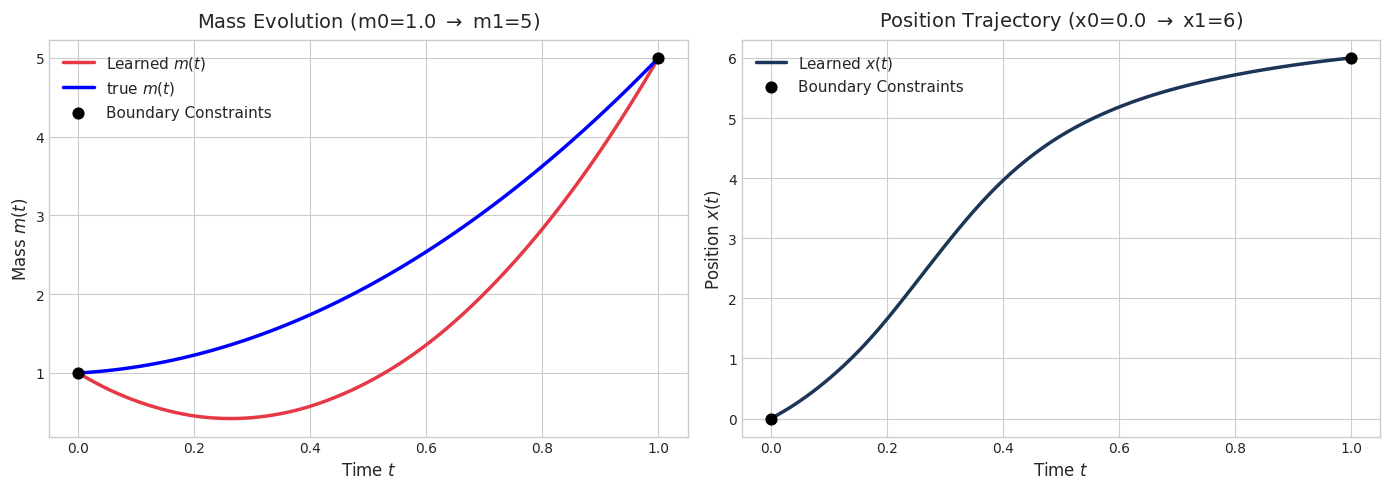

In [6]:
visualize_optimal_trajectory(path_model, d_val=6, m_val=5, device=device, delta=delta)


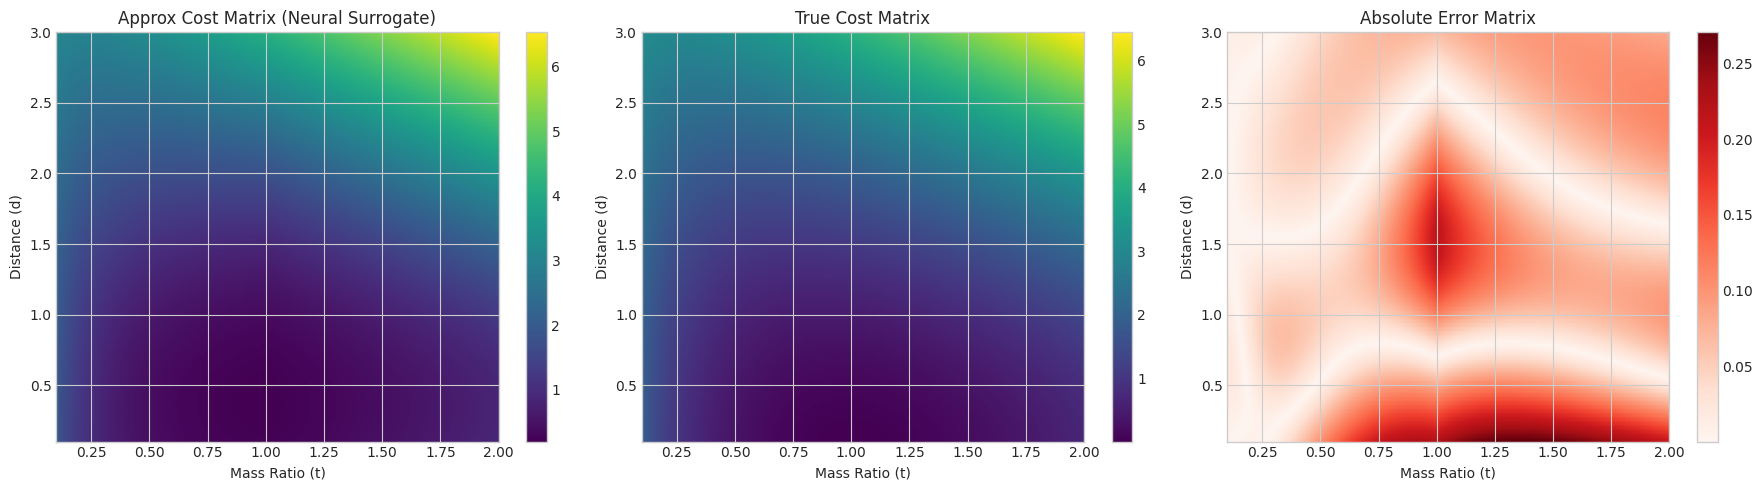

In [7]:
import matplotlib.pyplot as plt
import torch
import numpy as np


d_1d = torch.linspace(0.1, 3, 100)
t_1d = torch.linspace(0.1, 2, 200)


D, T = torch.meshgrid(d_1d, t_1d, indexing='ij')


cost_model.cpu().eval()


with torch.no_grad():
    cost_approx = cost_model(D, T).numpy()


cost_true = 2 * delta**2 * (1 + T - 2 * torch.sqrt(T) * torch.cos(torch.clamp(D / (2*delta), min=0.0, max=torch.pi/2)))
cost_true = cost_true.numpy()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


extent = [t_1d.min().item(), t_1d.max().item(), d_1d.min().item(), d_1d.max().item()]


im0 = axes[0].imshow(cost_approx, origin='lower', aspect='auto', extent=extent, cmap='viridis')
axes[0].set_title('Approx Cost Matrix (Neural Surrogate)')
axes[0].set_xlabel('Mass Ratio (t)')
axes[0].set_ylabel('Distance (d)')
fig.colorbar(im0, ax=axes[0])


im1 = axes[1].imshow(cost_true, origin='lower', aspect='auto', extent=extent, cmap='viridis')
axes[1].set_title('True Cost Matrix')
axes[1].set_xlabel('Mass Ratio (t)')
axes[1].set_ylabel('Distance (d)')
fig.colorbar(im1, ax=axes[1])


error_matrix = np.abs(cost_approx - cost_true)
im2 = axes[2].imshow(error_matrix, origin='lower', aspect='auto', extent=extent, cmap='Reds')
axes[2].set_title('Absolute Error Matrix')
axes[2].set_xlabel('Mass Ratio (t)')
axes[2].set_ylabel('Distance (d)')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()


## Flow matching and evaluation

In [8]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import time as TIME
from utils import sample_from_ot_plan, Possion_Bridge, SDE, wasserstein, wasserstein_with_weights, plot_comparisions, plot_k_values


print("\n" + "="*60)
print("PART 1: Computing Multi-Time Semi-Couplings via Robust PGD")
print("="*60)

cost_model = cost_model.to(device)
# Estimate a semi-coupling for each adjacent snapshot pair.
gamma0_plans_np = []
gamma1_plans_np = []
num_intervals = len(Xs) - 1

start_t = TIME.perf_counter()
for k in range(num_intervals):
    print(f"Computing PGD coupling for interval {k} -> {k+1} ...")
    Xk_tensor = torch.tensor(Xs[k], dtype=torch.float32, device=device)
    Xk1_tensor = torch.tensor(Xs[k+1], dtype=torch.float32, device=device)


    Gamma1_opt, Gamma2_opt = compute_approx_semi_coupling_Entropic_PGD(
        Xk_tensor, Xk1_tensor, cost_model, initial_lr=1e-4, epsilon=0, num_iters=2000, delta=delta
    )

    gamma0_plans_np.append(Gamma1_opt.cpu().detach().numpy())
    gamma1_plans_np.append(Gamma2_opt.cpu().detach().numpy())

print(f"All couplings computed in {TIME.perf_counter() - start_t:.2f}s")



PART 1: Computing Multi-Time Semi-Couplings via Robust PGD
Computing PGD coupling for interval 0 -> 1 ...


Computing UOT plans...: 100%|██████████| 1/1 [00:00<00:00,  2.98it/s]

True
true_action 4957.658676108056
Step   0 | Total Loss: 5028.3809 | Physics Cost: 5028.3809



/tmp/ipykernel_687021/2861261834.py:775: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Gamma1 = torch.tensor(Gamma1, dtype=torch.float32)
/tmp/ipykernel_687021/2861261834.py:776: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Gamma2 = torch.tensor(Gamma2, dtype=torch.float32)


Step  50 | Total Loss: 5027.8467 | Physics Cost: 5027.8467
Step 100 | Total Loss: 5027.9644 | Physics Cost: 5027.9644
Step 150 | Total Loss: 5028.3184 | Physics Cost: 5028.3184
Step 200 | Total Loss: 5028.8794 | Physics Cost: 5028.8794
Step 250 | Total Loss: 5029.8926 | Physics Cost: 5029.8926
Step 300 | Total Loss: 5030.1382 | Physics Cost: 5030.1382
Step 350 | Total Loss: 5029.5781 | Physics Cost: 5029.5781
Step 400 | Total Loss: 5029.3486 | Physics Cost: 5029.3486
Step 450 | Total Loss: 5029.5078 | Physics Cost: 5029.5078
Step 500 | Total Loss: 5028.9697 | Physics Cost: 5028.9697
Step 550 | Total Loss: 5029.2295 | Physics Cost: 5029.2295
Step 600 | Total Loss: 5028.7031 | Physics Cost: 5028.7031
Step 650 | Total Loss: 5028.9072 | Physics Cost: 5028.9072
Step 700 | Total Loss: 5028.8354 | Physics Cost: 5028.8354
Step 750 | Total Loss: 5028.2285 | Physics Cost: 5028.2285
Step 800 | Total Loss: 5028.5615 | Physics Cost: 5028.5615
Step 850 | Total Loss: 5027.8286 | Physics Cost: 5027.82

In [9]:
print("\n" + "="*60)
print("PART 2: Pre-sampling Global Training Data")
print("="*60)

# Sample endpoint pairs and mass ratios from the semi-couplings.
all_x0, all_x1, all_m0, all_m1, all_t_start, all_dt = [], [], [], [], [], []
t_train = np.arange(len(Xs)).tolist()
samples_per_interval = Xs[0].shape[0] * 5

for k in range(num_intervals):
    gamma0_plan = gamma0_plans_np[k]
    gamma1_plan = gamma1_plans_np[k]
    Xk_np = Xs[k]
    Xk1_np = Xs[k+1]


    x0_np, x1_np, idx_0, idx_1 = sample_from_ot_plan(gamma0_plan, Xk_np, Xk1_np, samples_per_interval)


    ratio = (gamma1_plan[idx_0, idx_1] / (gamma0_plan[idx_0, idx_1] + 1e-12)).reshape(-1, 1)
    m1_np = np.log(1e-8 + ratio)
    m0_np = np.zeros_like(m1_np)


    t_s = t_train[k]
    d_t = t_train[k+1] - t_train[k]

    all_x0.append(torch.tensor(x0_np, dtype=torch.float32))
    all_x1.append(torch.tensor(x1_np, dtype=torch.float32))
    all_m0.append(torch.tensor(m0_np, dtype=torch.float32))
    all_m1.append(torch.tensor(m1_np, dtype=torch.float32))
    all_t_start.append(torch.full((len(x0_np), 1), t_s, dtype=torch.float32))
    all_dt.append(torch.full((len(x0_np), 1), d_t, dtype=torch.float32))


train_x0 = torch.cat(all_x0).to(device)
train_x1 = torch.cat(all_x1).to(device)
train_m0 = torch.cat(all_m0).to(device)
train_m1 = torch.cat(all_m1).to(device)
train_t_start = torch.cat(all_t_start).to(device)
train_dt = torch.cat(all_dt).to(device)

batch_size = 256
train_dataset = TensorDataset(train_x0, train_x1, train_m0, train_m1, train_t_start, train_dt)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
print(f'Global Data prepared. Total samples: {len(train_dataset)}. Batches per epoch: {len(train_loader)}')



PART 2: Pre-sampling Global Training Data
Global Data prepared. Total samples: 2500. Batches per epoch: 9


In [10]:
print("\n" + "="*60)
print("PART 3: Flow Matching Training with Surrogate Path")
print("="*60)

nu = 0.001
steps = 3000
dim = Xs[0].shape[1]


path_model.eval()
path_model.to(device)


# Train the shared velocity, score, and growth fields.
flow_model = Possion_Bridge([dim + 1, 256, 256, 256, 256, 256], nu=nu).to(device)
optimizer = torch.optim.Adam(flow_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=1e-5)

flow_model.train()
global_step = 0
keep_training = True

start_t = TIME.perf_counter()
while keep_training:
    for batch_idx, (b_x0, b_x1, b_m0, b_m1, b_ts, b_dt) in enumerate(train_loader):
        optimizer.zero_grad()


        relative_t = torch.rand((b_x0.shape[0], 1), device=device)
        real_t = b_dt * relative_t + b_ts


        d = torch.norm(b_x1 - b_x0, dim=-1, keepdim=True)
        m_ratio = torch.exp(b_m1 - b_m0)

        d_flat = d.squeeze(-1)
        m_ratio_flat = m_ratio.squeeze(-1)
        t_flat = relative_t.squeeze(-1).clone().requires_grad_(True)

        with torch.set_grad_enabled(True):
            m_t_1d, x_t_1d = path_model(d_flat, m_ratio_flat, t_flat)

            dm_dt_flat = torch.autograd.grad(
                outputs=m_t_1d, inputs=t_flat,
                grad_outputs=torch.ones_like(m_t_1d),
                create_graph=False, retain_graph=True
            )[0]

            dx_dt_flat = torch.autograd.grad(
                outputs=x_t_1d, inputs=t_flat,
                grad_outputs=torch.ones_like(x_t_1d),
                create_graph=False, retain_graph=False
            )[0]


        m_t_1d = m_t_1d.unsqueeze(-1).detach()
        x_t_1d = x_t_1d.unsqueeze(-1).detach()
        dm_dt = dm_dt_flat.unsqueeze(-1).detach()
        dx_dt = dx_dt_flat.unsqueeze(-1).detach()


        direction = (b_x1 - b_x0) / (d + 1e-8)
        xts_mean = b_x0 + x_t_1d * direction
        vts_samp = dx_dt * direction
        mts_samp = b_m0 + torch.log(m_t_1d + 1e-8)
        kts_samp = dm_dt / (m_t_1d + 1e-8)

        eps_samp = torch.randn_like(xts_mean)
        std = torch.sqrt(nu * relative_t * (1.0 - relative_t) + 1e-8)
        xts_samp = xts_mean + std * eps_samp


        kts_samp = kts_samp / b_dt
        vts_samp = vts_samp / b_dt


        v, s, k_out = flow_model.forward(xts_samp, real_t)

        weights = torch.exp(mts_samp)
        v_loss = torch.mean(torch.pow(v - vts_samp, 2) * weights)
        bridge_term = 2 * torch.sqrt(relative_t * (1 - relative_t)) / (nu + 1e-8)
        s_loss = torch.mean(torch.pow(bridge_term * s + eps_samp, 2) * weights)
        k_loss = torch.mean(torch.pow(k_out - kts_samp, 2) * weights)

        loss = v_loss + s_loss + k_loss
        loss.backward()
        optimizer.step()
        scheduler.step()

        global_step += 1

        if global_step % 500 == 0 or global_step == 1:
            print(f"  Step {global_step:4d}/{steps} | Total Loss: {loss.item():.4f} (v: {v_loss.item():.4f}, s: {s_loss.item():.4f}, k: {k_loss.item():.4f})")

        if global_step >= steps:
            keep_training = False
            break

print(f"Flow Matching Training completed in {TIME.perf_counter() - start_t:.2f}s")



PART 3: Flow Matching Training with Surrogate Path
  Step    1/3000 | Total Loss: 729.7367 (v: 0.0140, s: 724.7503, k: 4.9724)
  Step  500/3000 | Total Loss: 1.4721 (v: 0.0056, s: 1.4596, k: 0.0069)
  Step 1000/3000 | Total Loss: 1.4074 (v: 0.0047, s: 1.3996, k: 0.0030)
  Step 1500/3000 | Total Loss: 1.3918 (v: 0.0046, s: 1.3851, k: 0.0021)
  Step 2000/3000 | Total Loss: 1.4169 (v: 0.0043, s: 1.4118, k: 0.0008)
  Step 2500/3000 | Total Loss: 1.5464 (v: 0.0045, s: 1.5411, k: 0.0007)
  Step 3000/3000 | Total Loss: 1.3819 (v: 0.0035, s: 1.3777, k: 0.0007)
Flow Matching Training completed in 23.15s


In [11]:
print("\n" + "="*60)
print("PART 4: Global Inference and Multi-time Evaluation")
print("="*60)

flow_model.eval()
flow_model.to('cpu')

# Generate trajectories and evaluate distribution and mass errors.
simulator = SDE(flow_model, nu, mode=1, positive=False)
x_source = torch.tensor(Xs[0], dtype=torch.float32, device='cpu')

max_sample_time = len(Xs) - 1

print(f'Simulating SDE Trajectories from t=0 to t={max_sample_time}...')
start_t = TIME.perf_counter()
xs, ms, action = simulator.trajectory(
    x=x_source,
    m=torch.zeros([x_source.size(0), 1], device='cpu'),
    delta=delta,
    T=max_sample_time,
    N=max_sample_time * 100
)
print(f"Simulation completed in {TIME.perf_counter() - start_t:.2f}s\n")


mass_ratios = [Xs[k].shape[0] / Xs[0].shape[0] for k in range(len(Xs))]

for k in range(1, len(Xs)):
    print(f"--- Evaluating Time Point {k} ---")
    timestep_idx = k * 100
    if timestep_idx >= xs.shape[0]:
        timestep_idx = xs.shape[0] - 1

    x1s_gen = xs[timestep_idx, :]
    m1s_gen = np.exp(ms[timestep_idx, :])


    wa_unnorm = wasserstein(torch.Tensor(np.array(x1s_gen)), torch.tensor(Xs[k], dtype=torch.float32), power=1)
    wa_norm = wasserstein_with_weights(torch.Tensor(np.array(x1s_gen)), np.array(m1s_gen), torch.Tensor(Xs[k]), np.ones(Xs[k].shape[0]), power=1)

    target_mass_ratio = mass_ratios[k]
    RME = np.abs((np.mean(m1s_gen) - target_mass_ratio) / target_mass_ratio)

    print(f"  Wasserstein (unnormalized): {wa_unnorm:.4f}")
    print(f"  Wasserstein (normalized)  : {wa_norm:.4f}")
    print(f"  Target Mass Ratio: {target_mass_ratio:.4f} | Generated Mass Mean: {np.mean(m1s_gen):.4f}")
    print(f"  Relative Mass Error (RME) : {RME:.4f}\n")



PART 4: Global Inference and Multi-time Evaluation
Simulating SDE Trajectories from t=0 to t=1...
Continuous inference
Simulation completed in 2.24s

--- Evaluating Time Point 1 ---
  Wasserstein (unnormalized): 3.0430
  Wasserstein (normalized)  : 2.3198
  Target Mass Ratio: 2.8000 | Generated Mass Mean: 2.6308
  Relative Mass Error (RME) : 0.0604



In [12]:
xs.shape
torch.save(flow_model, 'sudo_gaussian.pth')


In [13]:
from matplotlib.lines import Line2D
import seaborn as sns
def plot_comparisions(
    df, generated, trajectories,
    palette = 'viridis',
    df_time_key='samples',
    x='x1', y='x2',
    groups=None,
    save=True, path='comparision.png',
    legend_loc = 'upper right'
):
    if groups is None:
        groups = sorted(df[df_time_key].unique())
    cmap = plt.cm.viridis
    sns.set_palette(palette)
    plt.rcParams.update({
        'axes.prop_cycle': plt.cycler(color=cmap(np.linspace(0, 1, len(groups) + 1))),
        'axes.axisbelow': False,
        'axes.edgecolor': 'lightgrey',
        'axes.facecolor': 'None',
        'axes.grid': False,
        'axes.labelcolor': 'dimgrey',
        'axes.spines.right': False,
        'axes.spines.top': False,
        'figure.facecolor': 'white',
        'lines.solid_capstyle': 'round',
        'patch.edgecolor': 'w',
        'patch.force_edgecolor': True,
        'text.color': 'dimgrey',
        'xtick.bottom': False,
        'xtick.color': 'dimgrey',
        'xtick.direction': 'out',
        'xtick.top': False,
        'ytick.color': 'dimgrey',
        'ytick.direction': 'out',
        'ytick.left': False,
        'ytick.right': False,
        'font.size':12,
        'axes.titlesize':10,
        'axes.labelsize':12
    })

    n_cols = 1
    n_rols = 1

    grid_figsize = [12, 8]
    dpi = 300
    grid_figsize = (grid_figsize[0] * n_cols, grid_figsize[1] * n_rols)
    fig = plt.figure(None, grid_figsize, dpi=dpi)

    hspace = 0.3
    wspace = None
    gspec = plt.GridSpec(n_rols, n_cols, fig, hspace=hspace, wspace=wspace)

    outline_width = (0.3, 0.05)
    size = 300
    bg_width, gap_width = outline_width
    point = np.sqrt(size)

    gap_size = (point + (point * gap_width) * 2) ** 2
    bg_size = (np.sqrt(gap_size) + (point * bg_width) * 2) ** 2


    axs = []
    for i, gs in enumerate(gspec):
        ax = plt.subplot(gs)


        n = 0.3

        ax.scatter(
                df[x], df[y],
                c=df[df_time_key],
                s=size,
                alpha=0.7 * n,
                marker='X',
                linewidths=0,
                edgecolors=None,
                cmap=cmap
            )

        for trajectory in np.transpose(trajectories, axes=(1,0,2)):
                plt.plot(trajectory[:, 0], trajectory[:, 1], alpha=0.3, color='Black');

        states = sorted(df[df_time_key].unique())
        points = np.concatenate(generated, axis=0)
        n_gen = int(points.shape[0] / len(states))
        colors = [state for state in states for i in range(n_gen)]
        n = 1
        o = '.'
        ax.scatter(
                points[:, 0], points[:, 1],
                c='black',
                s=bg_size,
                alpha=1 * n,
                marker=o,
                linewidths=0,
                edgecolors=None
            )
        ax.scatter(
                points[:, 0], points[:, 1],
                c='white',
                s=gap_size,
                alpha=1 * n,
                marker=o,
                linewidths=0,
                edgecolors=None
            )
        pnts = ax.scatter(
                points[:, 0], points[:, 1],
                c=colors,
                s=size,
                alpha=0.7 * n,
                marker=o,
                linewidths=0,
                edgecolors=None,
                cmap=cmap
            )

        legend_elements = [
            Line2D(
                [0], [0], marker='o',
                color=cmap((i) / (len(states)-1)), label=f'T{state}',
                markerfacecolor=cmap((i) / (len(states)-1)), markersize=15,
            )
            for i, state in enumerate(states)
        ]

        leg = plt.legend(handles=legend_elements, loc='upper left', fontsize=30)
        ax.add_artist(leg)

        legend_elements = [
            Line2D(
                [0], [0], marker='X', color='w',
                label='Ground Truth', markerfacecolor=cmap(0), markersize=15, alpha=0.3
            ),
            Line2D([0], [0], marker='o', color='w', label='Predicted', markerfacecolor=cmap(.999), markersize=15),
            Line2D([0], [0], color='black', lw=2, label='Trajectory')

        ]
        leg = plt.legend(handles=legend_elements, loc=legend_loc, fontsize=30)
        ax.add_artist(leg)

        ax.set_xlabel("Gene $X_1$", fontsize=30)
        ax.set_ylabel("Gene $X_2$", fontsize=30)
        ax.get_xaxis().get_major_formatter().set_scientific(False)
        ax.get_yaxis().get_major_formatter().set_scientific(False)
        kwargs = dict(bottom=False, left=False, labelbottom=False, labelleft=False)
        ax.tick_params(which="both", **kwargs)

        ax.spines['left'].set_visible(True)
        ax.spines['bottom'].set_visible(True)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.patch.set_alpha(0)


        axs.append(ax)

    if save:

        try:
            fig.savefig(path, bbox_inches='tight')
        except ValueError:
            pass
    plt.close()
    return fig


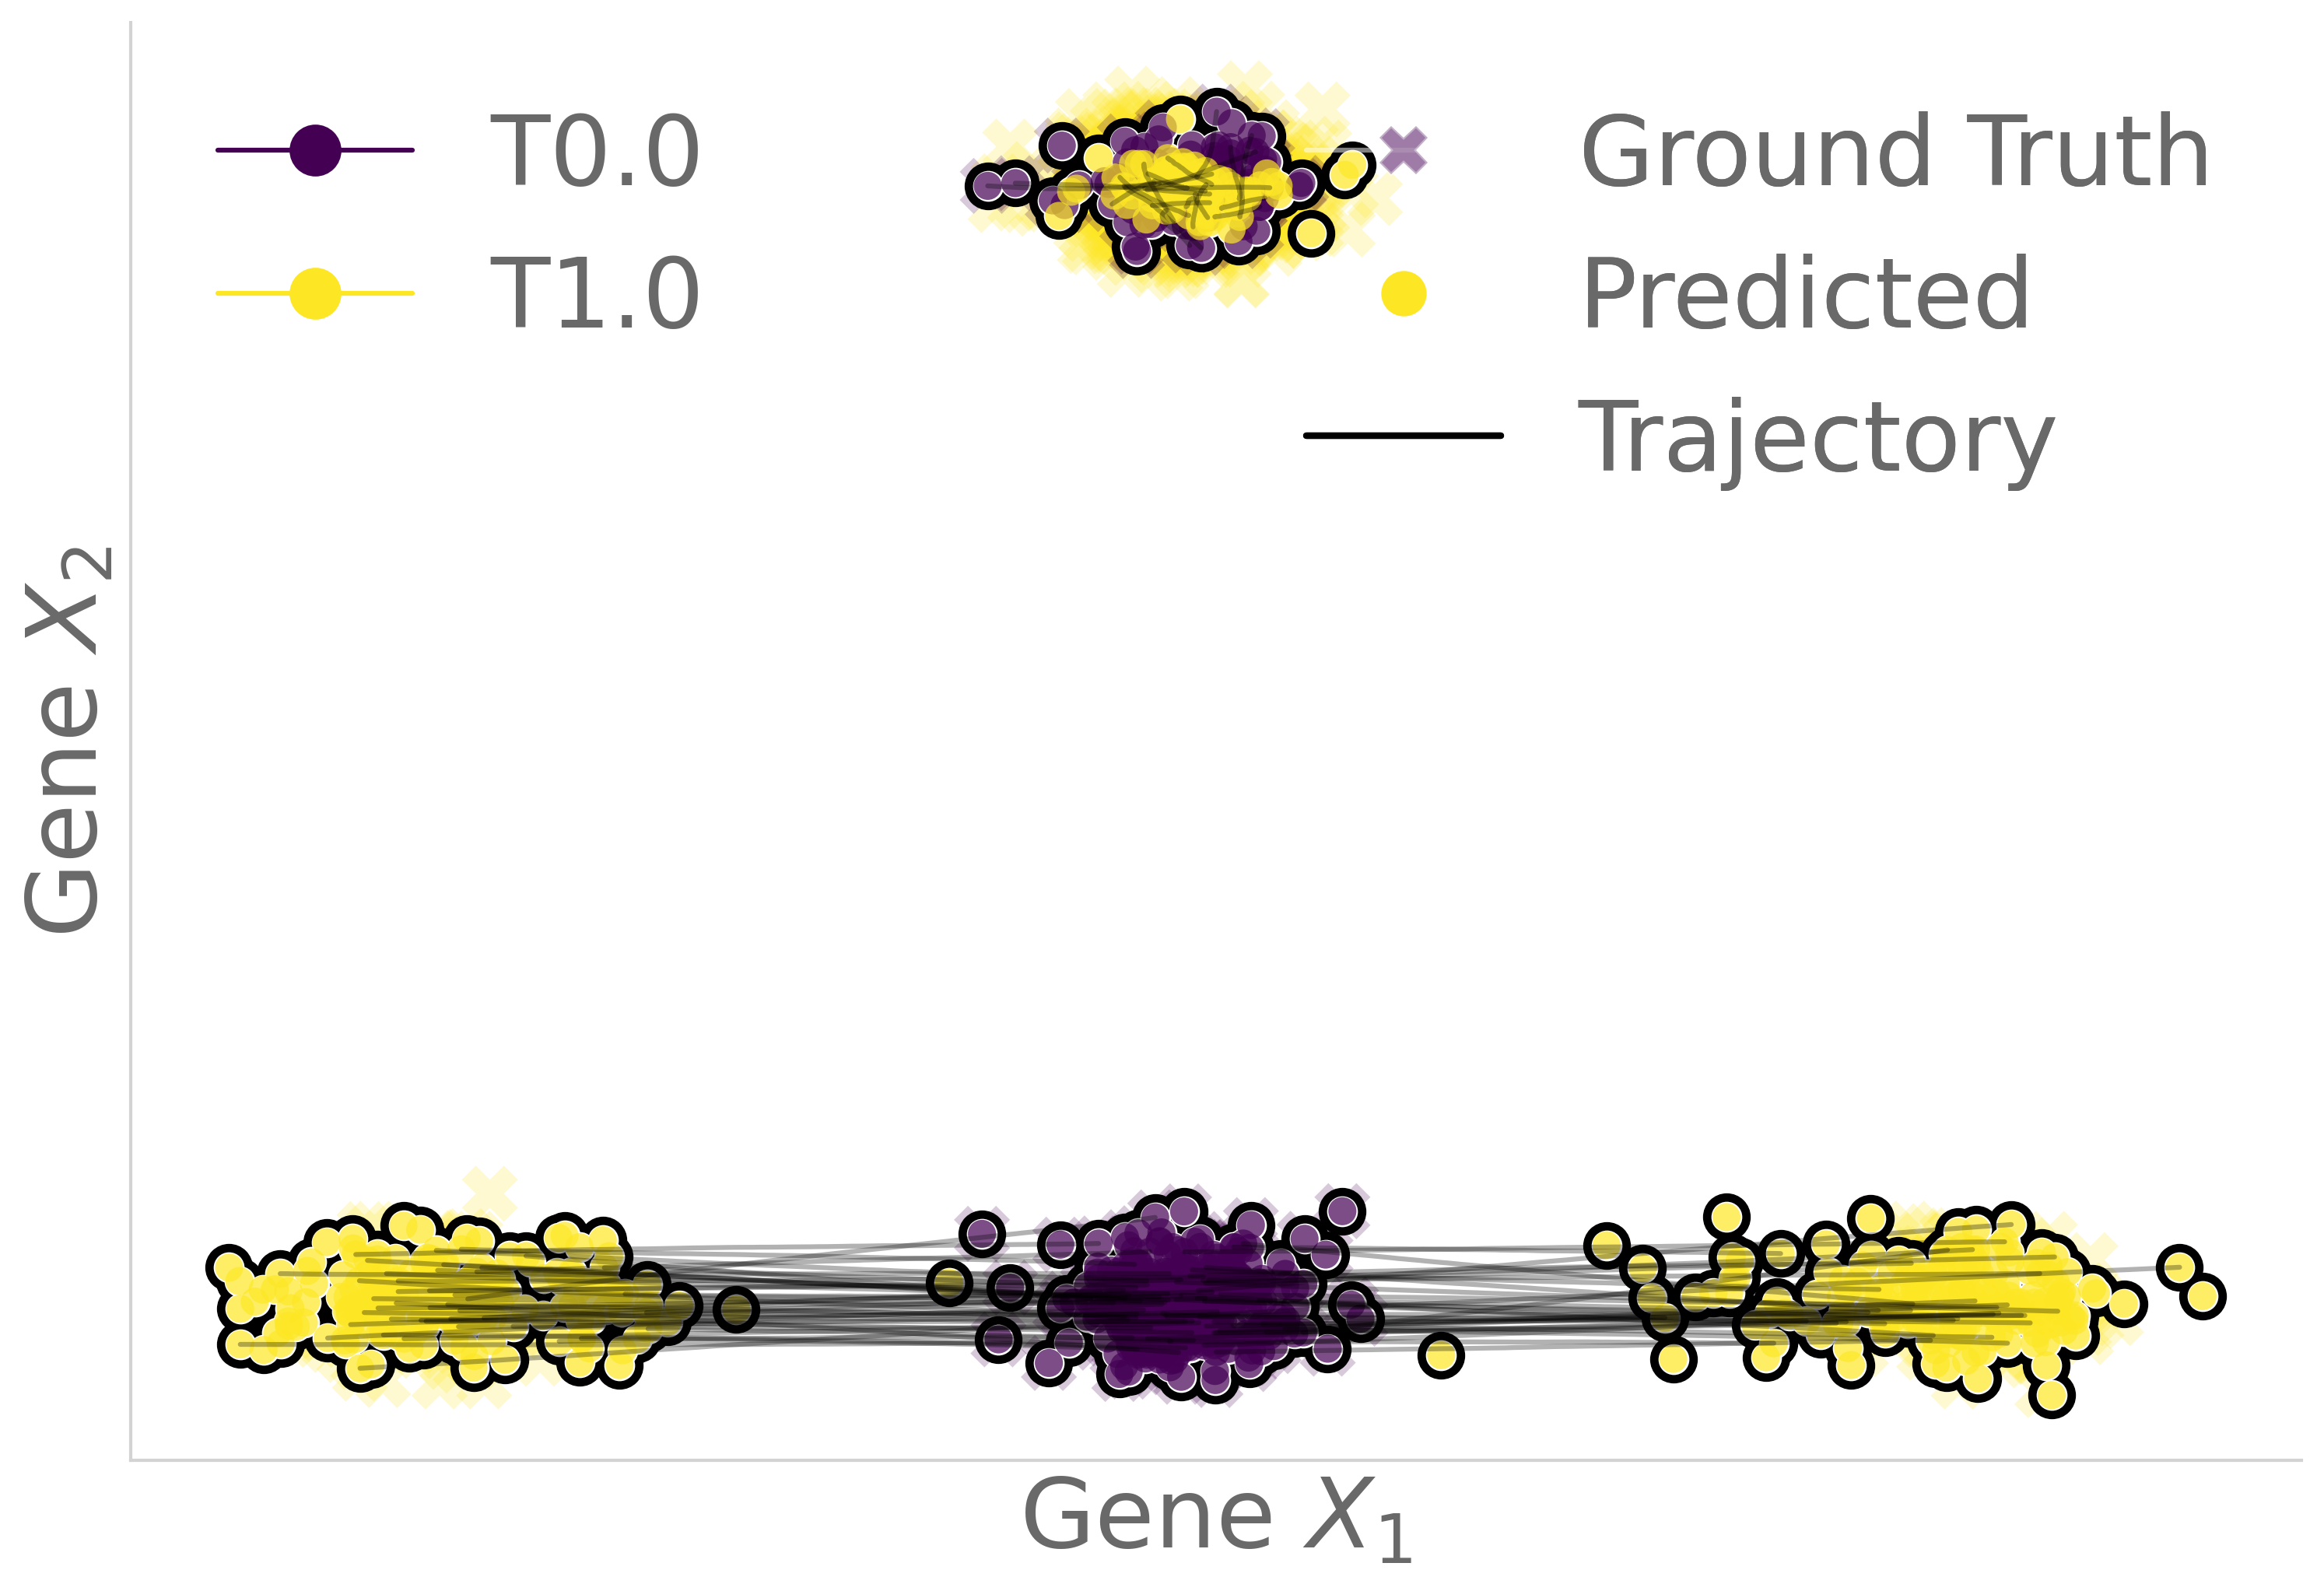

In [14]:
points = np.random.choice(xs.shape[1], size=100, replace=False)
generated = []
for time in range(len(Xs)):
    idx = time * 100
    if idx >= xs.shape[0]:
        idx = xs.shape[0] - 1
    generated.append(xs[idx, :])

plot_comparisions(data, generated, xs[:, points], path=f'wfr_gaussian.png', legend_loc='upper right')


In [15]:
_, _, g = flow_model(torch.tensor(np.array(data)[:,1:], dtype=torch.float32), torch.tensor(np.array(data)[:,0], dtype=torch.float32).reshape(-1,1))
_, _, g_middle = flow_model(torch.tensor(xs[50,:,:], dtype=torch.float32), 0.5*torch.tensor(np.ones_like(xs[50,:,0]), dtype=torch.float32).reshape(-1,1))
XX = np.concatenate([np.array(data)[:,1:], xs[50,:,:]])
gg = np.concatenate([g.detach().cpu().numpy(), g_middle.detach().cpu().numpy()], axis=0)


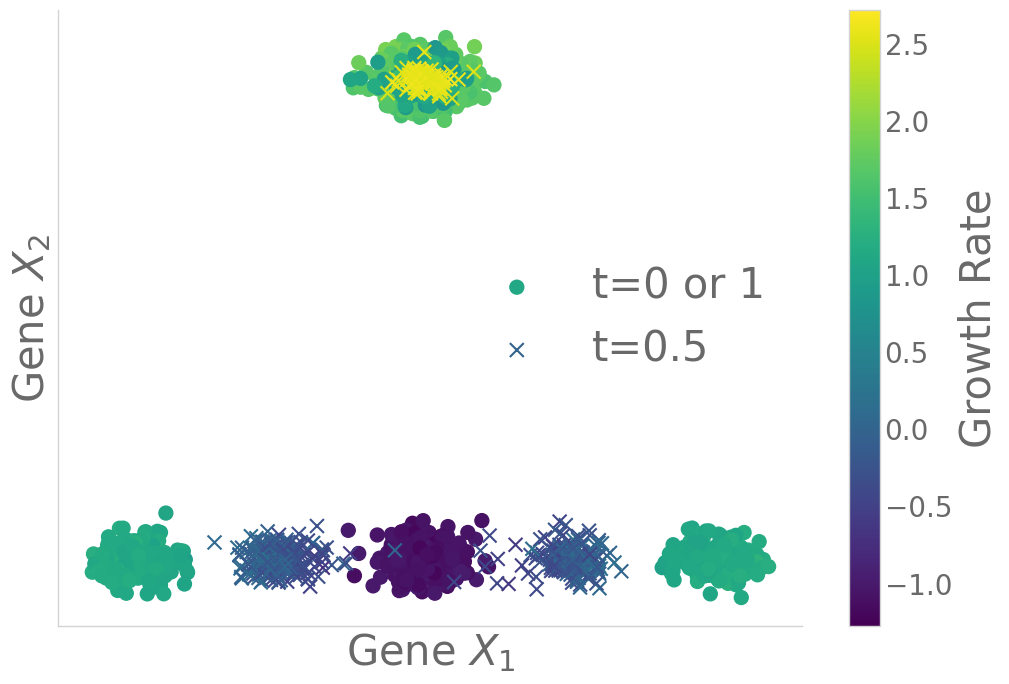

In [16]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))


c1 = g.detach().numpy()
c2 = g_middle.detach().numpy()


global_vmin = min(c1.min(), c2.min())
global_vmax = max(c1.max(), c2.max())


plt.scatter(np.array(data)[:, 1], np.array(data)[:, 2], c=c1, s=100, cmap='viridis', vmin=global_vmin, vmax=global_vmax, label='t=0 or 1', marker='o')
plt.scatter(xs[50, :, 0], xs[50, :, 1], c=c2, s=100, cmap='viridis', vmin=global_vmin, vmax=global_vmax, label='t=0.5', marker='x')

plt.xlabel("Gene $X_1$", fontsize=30)
plt.ylabel("Gene $X_2$", fontsize=30)
plt.xticks([])
plt.yticks([])

cbar = plt.colorbar()

cbar.set_label('Growth Rate', fontsize=30)
cbar.ax.tick_params(labelsize=20)
plt.legend(fontsize=30)

plt.savefig('g_wfr_gaussian.png')
plt.show()
